                                HEALTH RISK CLASSIFICATION
Name: Baheej Fatima                                            Roll No: 24F-AI-108

In [42]:
# importing libraries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier




In [19]:
# loading the dataset
df = pd.read_csv("diabetes.csv")

df.head(10)

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [22]:
# checking missing values in the dataset and handeling them 

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [23]:

# Filling the missing numerical values with median
imputer = SimpleImputer(strategy="median")

df[columns_with_zero] = imputer.fit_transform(
    df[columns_with_zero]
)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


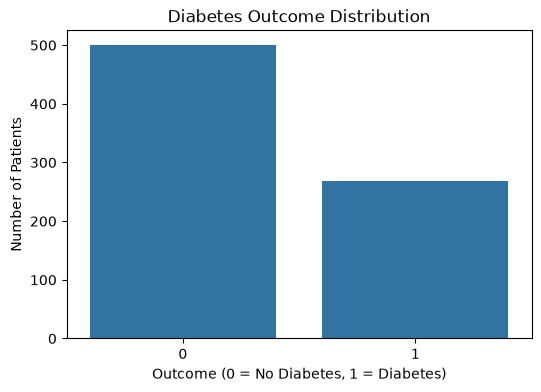

In [21]:
# Data Visualization

plt.figure(figsize=(6, 4))

sns.countplot(x="Outcome", data=df)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")

plt.show()

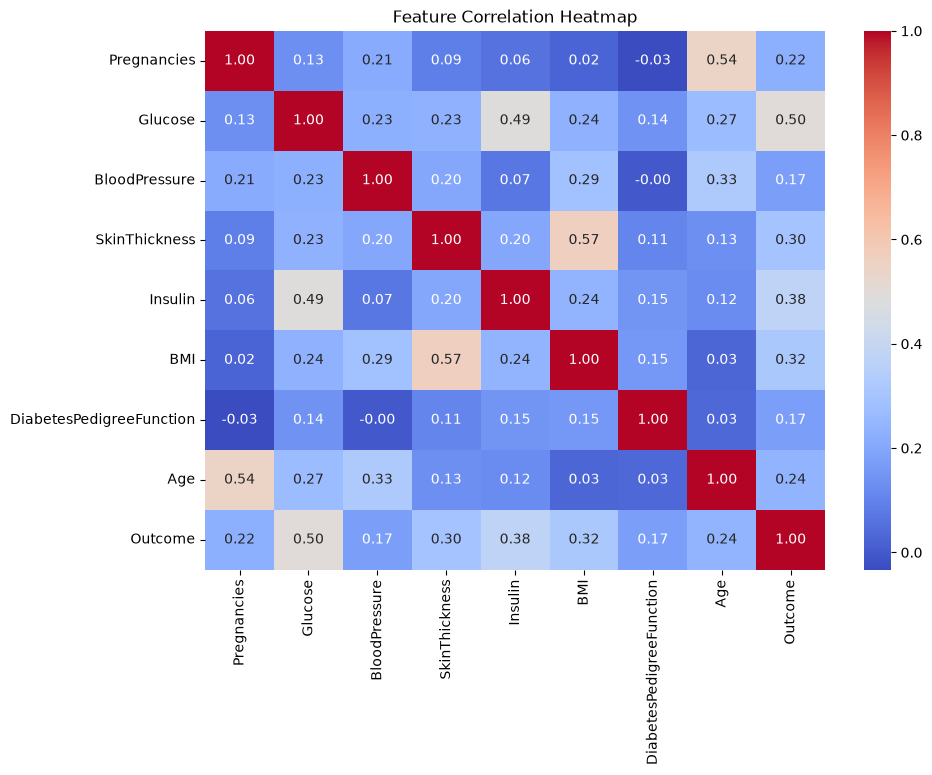

In [25]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [27]:
#Separating Features and target and splitting the data

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=47
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [29]:
# feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
# applying SVM model

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_train_pred = svm_model.predict(X_train_scaled)
svm_test_pred = svm_model.predict(X_test_scaled)

In [34]:
# SVM evaluation

svm_train_accuracy = accuracy_score(
    y_train,
    svm_train_pred
)

svm_test_accuracy = accuracy_score(
    y_test,
    svm_test_pred
)

print("SVM Training Accuracy:", svm_train_accuracy)
print("SVM Testing Accuracy:", svm_test_accuracy)

print("\nSVM Classification Report:")
print(
    classification_report(
        y_test,
        svm_test_pred
    )
)

SVM Training Accuracy: 0.8973941368078175
SVM Testing Accuracy: 0.8116883116883117

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87       108
           1       0.72      0.61      0.66        46

    accuracy                           0.81       154
   macro avg       0.78      0.75      0.76       154
weighted avg       0.81      0.81      0.81       154



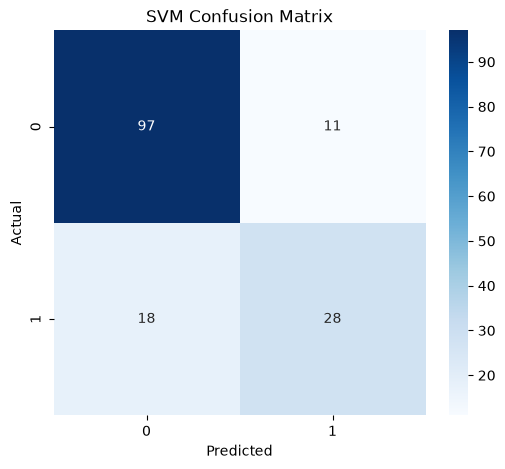

In [46]:
# SVM Confusion Matrix

cm_svm = confusion_matrix(
    y_test,
    svm_test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [37]:
# applying decision tree model

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_train_pred = dt_model.predict(X_train)
dt_test_pred = dt_model.predict(X_test)


In [38]:
# decision tree evaluation

dt_train_accuracy = accuracy_score(
    y_train,
    dt_train_pred
)

dt_test_accuracy = accuracy_score(
    y_test,
    dt_test_pred
)

print("Decision Tree Training Accuracy:", dt_train_accuracy)
print("Decision Tree Testing Accuracy:", dt_test_accuracy)

print("\nDecision Tree Classification Report:")

print(
    classification_report(
        y_test,
        dt_test_pred
    )
)

Decision Tree Training Accuracy: 0.9267100977198697
Decision Tree Testing Accuracy: 0.8831168831168831

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91       108
           1       0.77      0.87      0.82        46

    accuracy                           0.88       154
   macro avg       0.86      0.88      0.87       154
weighted avg       0.89      0.88      0.89       154



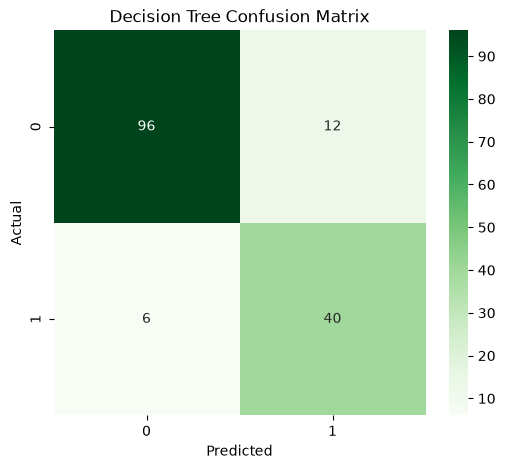

In [47]:
# Decision Tree Confusion Matrix

cm_dt = confusion_matrix(
    y_test,
    dt_test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
# Model comparision

results = pd.DataFrame({
    "Model": [
        "SVM",
        "Decision Tree"
    ],
    
    "Training Accuracy": [
        svm_train_accuracy,
        dt_train_accuracy
    ],
    
    "Testing Accuracy": [
        svm_test_accuracy,
        dt_test_accuracy
    ]
})

results

,Model,Training Accuracy,Testing Accuracy
0,SVM,0.897394,0.811688
1,Decision Tree,0.926710,0.883117


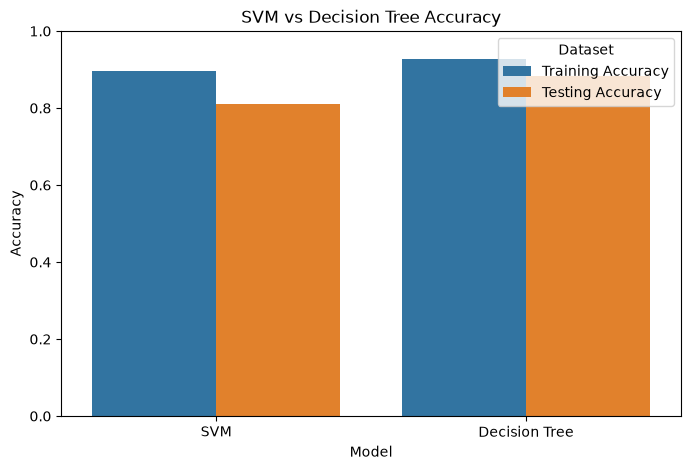

In [ ]:
# Visualizing model accuracy

results_melted = results.melt(
    id_vars="Model",
    value_vars=[
        "Training Accuracy",
        "Testing Accuracy"
    ],
    var_name="Dataset",
    value_name="Accuracy"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Accuracy",
    hue="Dataset"
)

plt.ylim(0, 1)
plt.title("SVM vs Decision Tree Accuracy")
plt.show()

In [ ]:
# detailed comparision

models = {
    "SVM": svm_test_pred,
    "Decision Tree": dt_test_pred
}

comparison = []

for model_name, predictions in models.items():
    
    comparison.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.811688,0.717949,0.608696,0.658824
1,Decision Tree,0.883117,0.769231,0.869565,0.816327


In [ ]:
# CONCLUSION

best_model = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print("FINAL MODEL COMPARISON")

print(comparison_df)

print("\nBest Model:")
print(best_model["Model"])

print("\nBest Testing Accuracy:")
print(best_model["Accuracy"])

       FINAL MODEL COMPARISON
           Model  Accuracy  Precision    Recall  F1 Score
0            SVM  0.811688   0.717949  0.608696  0.658824
1  Decision Tree  0.883117   0.769231  0.869565  0.816327

Best Model:
Decision Tree

Best Testing Accuracy:
0.8831168831168831
